<a href="https://colab.research.google.com/github/Saumyam246/Machine-Learning-Final-Project/blob/main/Unit_3_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)
from scipy.cluster.hierarchy import linkage, fcluster


In [ ]:

df = pd.read_csv("unsupervised_image_features.csv")

print("Dataset Shape:", df.shape)
display(df.head())

X = df.drop(columns=["image_name"])

print("Input Features:", X.shape[1])
print("Number of Samples:", X.shape[0])


Dataset Shape: (237, 97)


,image_name,R_1,R_2,R_3,R_4,R_5,R_6,R_7,R_8,R_9,...,B_23,B_24,B_25,B_26,B_27,B_28,B_29,B_30,B_31,B_32
0,0000.png,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,...,0.055288,0.117500,0.193871,0.193008,0.166154,0.099966,0.054019,0.033749,0.018000,0.029366
1,0001.png,0.0,0.0,0.0,0.0,0.0,0.0,0.000002,0.000094,0.000471,...,0.042778,0.081940,0.123359,0.145769,0.203150,0.168397,0.084192,0.047719,0.024065,0.034847
2,0002.png,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,...,0.145619,0.182409,0.160474,0.105413,0.076530,0.045042,0.022069,0.012282,0.005563,0.003574
3,0003.png,0.0,0.0,0.0,0.0,0.0,0.0,0.000015,0.000330,0.001024,...,0.104403,0.151777,0.165196,0.135668,0.120815,0.078147,0.038009,0.021031,0.009901,0.012621
4,0004.png,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,...,0.085838,0.165844,0.225083,0.180063,0.136934,0.070963,0.031084,0.015942,0.006724,0.003929


Input Features: 96
Number of Samples: 237


In [ ]:

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Remove constant features
feature_variance = X_scaled.var(axis=0)
X_scaled = X_scaled[:, feature_variance > 0]

print("Final Data Shape:", X_scaled.shape)


Final Data Shape: (237, 88)


In [ ]:

pca = PCA(n_components=0.95)

X_pca = pca.fit_transform(X_scaled)

print("Original Features:", X_scaled.shape[1])
print("Reduced Features:", X_pca.shape[1])
print("Variance Retained:", pca.explained_variance_ratio_.sum())


Original Features: 88
Reduced Features: 23
Variance Retained: 0.9508377216612837


In [ ]:

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

print("K-Means Clustering Completed")
print("Cluster Distribution:")
print(pd.Series(kmeans_labels).value_counts().sort_index())


K-Means Clustering Completed
Cluster Distribution:
0    110
1     92
2     34
3      1
Name: count, dtype: int64


In [ ]:

linkage_matrix = linkage(X_scaled, method="ward")

hierarchical_labels = fcluster(
    linkage_matrix,
    t=4,
    criterion="maxclust"
) - 1

print("Hierarchical Clustering Completed")
print("Cluster Distribution:")
print(pd.Series(hierarchical_labels).value_counts().sort_index())


Hierarchical Clustering Completed
Cluster Distribution:
0    119
1     77
2     40
3      1
Name: count, dtype: int64


In [ ]:

comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "Hierarchical Clustering"],

    "Silhouette Score": [
        silhouette_score(X_scaled, kmeans_labels),
        silhouette_score(X_scaled, hierarchical_labels)
    ],

    "Calinski-Harabasz Score": [
        calinski_harabasz_score(X_scaled, kmeans_labels),
        calinski_harabasz_score(X_scaled, hierarchical_labels)
    ],

    "Davies-Bouldin Score": [
        davies_bouldin_score(X_scaled, kmeans_labels),
        davies_bouldin_score(X_scaled, hierarchical_labels)
    ]
})

display(comparison.round(4))


,Algorithm,Silhouette Score,Calinski-Harabasz Score,Davies-Bouldin Score
0,K-Means,0.1620,44.2302,1.4588
1,Hierarchical Clustering,0.1357,40.8778,1.5744


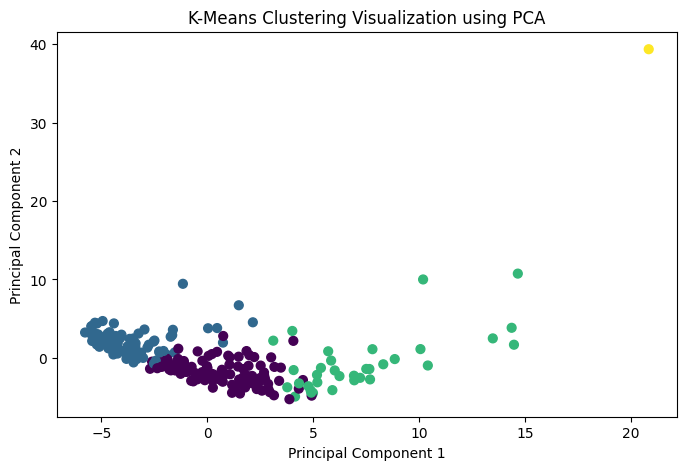

In [ ]:

plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    s=40
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering Visualization using PCA")
plt.show()
